| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../12_DEEP_LEARNING/12_2_Arquitecturas.ipynb) | [⏩](../13_MODELAMIENTO_CIENTIFICO/13_1_Modelos_fisicos.ipynb) |

# 12.3 Matemática del Deep Learning: cadena, Jacobianos y derivadas físicas

**Objetivo del cuaderno.** analizar el flujo de gradientes, verificar autodiferenciación de orden alto y entender el papel de escala y representación

**Antes de empezar:** regla de la cadena, Jacobiano, Hessiano y redes neuronales. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)
import torch
from torch import nn
torch.manual_seed(42)
torch.set_num_threads(1)
print('PyTorch:', torch.__version__, '| dispositivo: CPU')

PyTorch: 2.14.1+cpu | dispositivo: CPU


## 1. Una red es una composición de mapas

Si $f=f_L\circ\cdots\circ f_1$, la regla de la cadena da

$$D_xf=Df_L(h_{L-1})\cdots Df_1(x).$$

Para una capa $h=\sigma(Wx+b)$, su Jacobiano es $D=\operatorname{diag}(\sigma'(Wx+b))W$. Las normas de estos productos pueden decaer o crecer con profundidad. Esta es una explicación de gradientes desvanecidos y explosivos, aunque los productos reales dependen de datos y direcciones, no solo de un escalar.

## 2. Retropropagación es diferenciación en modo inverso

Para una pérdida escalar y muchos parámetros, el modo inverso calcula productos vector-Jacobiano reutilizando operaciones del forward pass. No aproxima derivadas mediante perturbaciones de cada peso: aplica derivadas locales por cadena. Su precisión está limitada por aritmética y operaciones usadas, y no hace suaves operaciones que no lo son.

El modo directo calcula productos Jacobiano-vector y puede ser útil con pocas entradas y muchas salidas. Autodiferenciación y diferenciación simbólica son mecanismos distintos. Un programa diferenciable sigue necesitando un modelo científicamente válido.

## 3. Gradientes a través de un producto de matrices

Aislamos el efecto de normas: una pila de matrices $W_l=sQ_l$ con $Q_l$ ortogonales conserva norma si $s=1$, la reduce si $s<1$ y la amplifica si $s>1$. Aquí no hay activaciones; es un experimento controlado de geometría lineal.

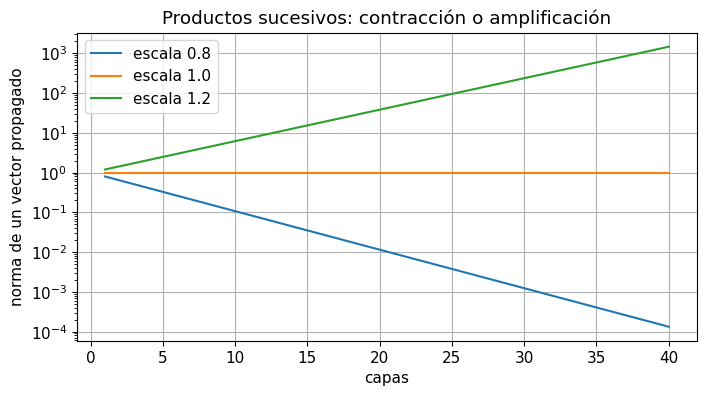

In [2]:
dimension=12;depths=np.arange(1,41)
base=[]
for _ in depths:
    Q,_=np.linalg.qr(rng.normal(size=(dimension,dimension)));base.append(Q)
for scale in [0.8,1.,1.2]:
    vector=np.ones(dimension)/np.sqrt(dimension);norms=[]
    for Q in base:
        vector=scale*Q@vector;norms.append(np.linalg.norm(vector))
    plt.semilogy(depths,norms,label=f'escala {scale}')
plt.xlabel('capas');plt.ylabel('norma de un vector propagado');plt.title('Productos sucesivos: contracción o amplificación');plt.legend();plt.show()

**Interpretación.** Una pequeña desviación respecto a escala uno puede acumularse exponencialmente. Las inicializaciones Xavier y Kaiming intentan controlar escalas de activaciones/gradientes bajo hipótesis aproximadas. Normalizaciones y conexiones residuales cambian la dinámica, pero deben evaluarse en la red concreta.

## 4. Derivadas respecto a parámetros y coordenadas

En aprendizaje supervisado necesitamos $\partial J/\partial\theta$. En PINNs necesitamos además $u_x,u_t,u_{xx}$ y luego derivar la pérdida física respecto a $\theta$. Para derivar una derivada, PyTorch debe construir su grafo con `create_graph=True`.

Usar `.detach()` o convertir a NumPy corta el grafo. Es correcto para visualizar, pero incorrecto antes de una derivada que debe contribuir al entrenamiento. El tipo float64 puede ayudar a verificar derivadas y residuales pequeños; no elimina errores de modelamiento.

## 5. Campo exacto para una ecuación de calor

Para $u(x,t)=\sin(\pi x)e^{-\nu\pi^2t}$ se cumple $u_t-\nu u_{xx}=0$ y $u(0,t)=u(1,t)=0$. Construimos este campo con operaciones de PyTorch y comprobamos derivadas con expresiones analíticas. No estamos entrenando una PINN: verificamos el mecanismo de derivación que utilizará.

In [3]:
nu=0.2
coordinates=torch.tensor(rng.uniform([0,0],[1,1],(100,2)),dtype=torch.float64,requires_grad=True)
x=coordinates[:,0:1];t=coordinates[:,1:2]
u=torch.sin(torch.pi*x)*torch.exp(-nu*torch.pi**2*t)
first=torch.autograd.grad(u,coordinates,grad_outputs=torch.ones_like(u),create_graph=True)[0]
ux=first[:,0:1];ut=first[:,1:2]
second=torch.autograd.grad(ux,coordinates,grad_outputs=torch.ones_like(ux),create_graph=True)[0]
uxx=second[:,0:1]
residual=ut-nu*uxx
ux_true=torch.pi*torch.cos(torch.pi*x)*torch.exp(-nu*torch.pi**2*t)
print('Máximo error ux:',(ux-ux_true).abs().max().item())
print('Máximo residual calor:',residual.abs().max().item())
assert residual.abs().max().item()<1e-12

Máximo error ux: 4.440892098500626e-16
Máximo residual calor: 4.440892098500626e-16


## 6. Construir una pérdida física y calcular su gradiente

Una red $u_\theta(x,t)$ puede aproximar el campo. La pérdida de residual se estima en puntos de colocación y se combina con condiciones iniciales y de borde:

$$J=\lambda_r\,\operatorname{mean}(u_t-\nu u_{xx})^2+\lambda_0\,\operatorname{mean}(u(x,0)-u_0)^2+\lambda_b\,\operatorname{mean}(u|_{\partial\Omega})^2.$$

Minimizar residual en una malla finita no prueba que la PDE se cumpla en todos los puntos. Hay que evaluar con puntos nuevos y métricas de solución. Si omitimos condiciones iniciales/borde, el campo cero puede satisfacer el residual sin representar la solución buscada.

El ejemplo siguiente solo verifica que la pérdida de residual de una red aleatoria llega a sus parámetros. No afirma que esa red haya aprendido la ecuación.

In [4]:
network=nn.Sequential(nn.Linear(2,16),nn.Tanh(),nn.Linear(16,16),nn.Tanh(),nn.Linear(16,1)).double()
coords=coordinates.detach().clone().requires_grad_(True)
pred=network(coords)
d1=torch.autograd.grad(pred,coords,torch.ones_like(pred),create_graph=True)[0]
d2=torch.autograd.grad(d1[:,0:1],coords,torch.ones_like(pred),create_graph=True)[0]
r=d1[:,1:2]-nu*d2[:,0:1]
physics_loss=(r*r).mean()
network.zero_grad();physics_loss.backward()
for name,param in network.named_parameters():
    norm=None if param.grad is None else param.grad.norm().item()
    print(name,'norma gradiente=',norm)
print('Residual medio de red aleatoria:',physics_loss.item())
print('El sesgo final constante no afecta este residual y puede tener gradiente ausente.')

0.weight norma gradiente= 0.01848318076435693
0.bias norma gradiente= 0.007270987803159614
2.weight norma gradiente= 0.055069198214428364
2.bias norma gradiente= 0.002379985217338313
4.weight norma gradiente= 0.05115020041404666
4.bias norma gradiente= None
Residual medio de red aleatoria: 0.0017955221730716919
El sesgo final constante no afecta este residual y puede tener gradiente ausente.


## 7. Normalización y regla de la cadena física

Si $\xi=(x-x_0)/L$ y $\tau=t/T$, entonces $u_x=L^{-1}u_\xi$, $u_{xx}=L^{-2}u_{\xi\xi}$ y $u_t=T^{-1}u_\tau$. El residual físico es

$$\frac1T u_\tau-\frac\nu{L^2}u_{\xi\xi}.$$

Olvidar estos factores cambia la ecuación que se entrena. Normalizar datos y adimensionalizar una PDE deben conectarse explícitamente. Las pérdidas física y de datos pueden tener unidades diferentes; sus pesos requieren interpretación.

## 8. Comprobar el efecto de escalar coordenadas

Tomamos $L=2$, $T=3$ y un campo que resuelve difusión en coordenadas físicas. El residual con los factores correctos se anula; el residual que los omite generalmente no.

Residual correcto máximo: 5.551115123125783e-17 Incorrecto: 0.46181147702163106


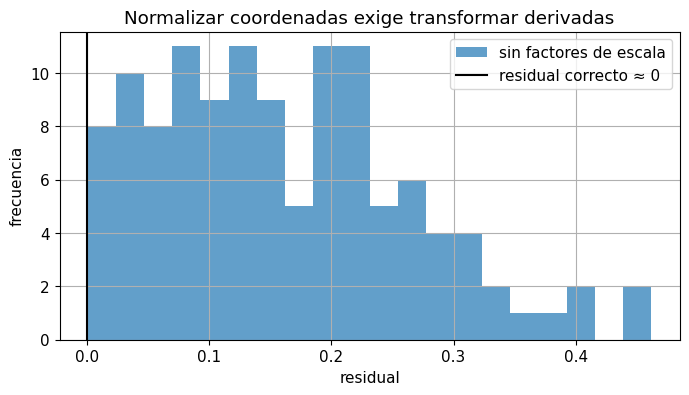

In [5]:
L=2.;T=3.
q=torch.tensor(rng.uniform(0,1,(120,2)),dtype=torch.float64,requires_grad=True)
xi=q[:,0:1];tau=q[:,1:2]
field=torch.sin(torch.pi*xi)*torch.exp(-nu*torch.pi**2*T*tau/L**2)
d=torch.autograd.grad(field,q,torch.ones_like(field),create_graph=True)[0]
dd=torch.autograd.grad(d[:,0:1],q,torch.ones_like(field),create_graph=True)[0]
correct=d[:,1:2]/T-nu*dd[:,0:1]/L**2
wrong=d[:,1:2]-nu*dd[:,0:1]
plt.hist(wrong.detach().numpy().ravel(),bins=20,alpha=0.7,label='sin factores de escala')
plt.axvline(0,c='k',label='residual correcto ≈ 0');plt.xlabel('residual');plt.ylabel('frecuencia')
plt.title('Normalizar coordenadas exige transformar derivadas');plt.legend();plt.show()
print('Residual correcto máximo:',correct.abs().max().item(),'Incorrecto:',wrong.abs().max().item())
assert correct.abs().max().item()<1e-12

## 9. Condiciones exactas mediante parametrización

Podemos definir $u_\theta(x,t)=x(1-x)N_\theta(x,t)$ para imponer exactamente bordes homogéneos en $[0,1]$. Si además queremos condición inicial $u_0(x)$ compatible, una construcción es $u_\theta=u_0(x)+t x(1-x)N_\theta$, siempre que el término inicial cumpla los bordes requeridos.

La parametrización cambia la geometría de optimización y las derivadas. Imponer una condición exacta no elimina la necesidad de minimizar la PDE ni garantiza buena aproximación. La compatibilidad entre condición inicial y de borde es parte del modelo.

## 10. Error de valores frente a error de derivadas

Un ejemplo analítico muestra el problema: $\tilde u(x)=\sin(\pi x)+\epsilon\sin(k\pi x)$. El error de valores tiene amplitud $\epsilon$, pero el de primera derivada tiene amplitud $\epsilon k\pi$ y el de segunda derivada $\epsilon(k\pi)^2$. Una perturbación pequeña y muy oscilatoria puede dominar un residual de segundo orden.

RMSE valores / primera / segunda: 0.007067531393633849 0.4445103824544584 27.901495578978334


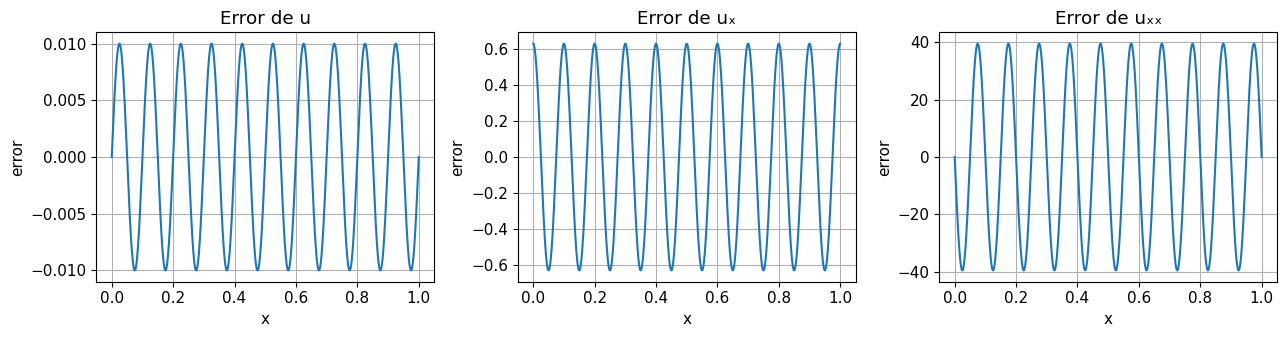

In [6]:
xx=np.linspace(0,1,1000);epsilon=0.01;k=20
value_error=epsilon*np.sin(k*np.pi*xx)
derivative_error=epsilon*k*np.pi*np.cos(k*np.pi*xx)
second_error=-epsilon*(k*np.pi)**2*np.sin(k*np.pi*xx)
fig,ax=plt.subplots(1,3,figsize=(13,3.5))
for a,error,title in zip(ax,[value_error,derivative_error,second_error],['Error de u','Error de uₓ','Error de uₓₓ']):
    a.plot(xx,error);a.set(xlabel='x',ylabel='error',title=title)
plt.tight_layout();plt.show()
print('RMSE valores / primera / segunda:',*[np.sqrt(np.mean(e*e)) for e in [value_error,derivative_error,second_error]])

**Interpretación.** Las escalas verticales cambian mucho entre paneles. Una métrica de valores puede ocultar errores grandes de derivadas. La malla de evaluación también debe resolver oscilaciones: puntos insuficientes pueden omitir el problema por aliasing.

## 11. Frecuencias, representación y dificultad de entrenamiento

En algunos regímenes, redes y entrenamiento aprenden primero componentes suaves; se suele llamar sesgo espectral a ese comportamiento observado. No es una ley idéntica para todas las arquitecturas, activaciones y optimizadores. Características de Fourier o activaciones periódicas pueden representar frecuencias altas más directamente, pero alteran sensibilidad y necesidad de datos.

Las propiedades de aproximación son diferentes de la facilidad de optimización. Una red puede representar una solución y aun así ser difícil de entrenar por pérdidas rígidas, mala escala o gradientes competidores.

## 12. Derivadas direccionales y Hessiano-vector

Un Hessiano denso es costoso. Para una pérdida escalar, el producto $Hv$ puede obtenerse derivando $g^Tv$ sin formar $H$. Esta idea aparece en métodos de segundo orden, análisis de sensibilidad y diferenciación implícita. La verificación por diferencias centrales sigue siendo útil para detectar errores en una implementación concreta.

In [7]:
theta=torch.tensor([0.3,-0.4],dtype=torch.float64,requires_grad=True)
loss=theta[0]**2+3*theta[1]**2+theta[0]*theta[1]
g=torch.autograd.grad(loss,theta,create_graph=True)[0]
v=torch.tensor([1.,2.],dtype=torch.float64)
Hv=torch.autograd.grad(g@v,theta)[0]
H=np.array([[2.,1.],[1.,6.]])
print('Hv autograd:',Hv.detach().numpy(),'Referencia:',H@v.numpy())
assert np.allclose(Hv.detach().numpy(),H@v.numpy())

Hv autograd: [ 4. 13.] Referencia: [ 4. 13.]


## Síntesis y conexión con Scientific Machine Learning

Las redes se estudian como composiciones de Jacobianos. Autograd facilita derivadas y productos de orden alto, pero las escalas, suavidad y operaciones del programa determinan qué ecuación se calcula. En SciML hay que verificar residuos, condiciones y errores de derivadas junto a la solución.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../12_DEEP_LEARNING/12_2_Arquitecturas.ipynb) | [⏩](../13_MODELAMIENTO_CIENTIFICO/13_1_Modelos_fisicos.ipynb) |